## Final Script Final Project


In [179]:
import pandas as pd
import igraph as ig

# Load the datasets 

# Load edge list
twitch_edges = pd.read_csv('twitch_edges.csv', sep='|')

# Load node features
twitch_nodes = pd.read_csv('twitch_features.csv', sep='|')

# Load interconnected edge list
inter_edges = pd.read_csv('twitch_intercommunity.csv', sep='|')


In [180]:
# Function to load the graphs

def make_graph(twitch_edges):
    # Step 2: Create list of edge tuples (numeric_id_1, numeric_id_2)
    edges = list(twitch_edges[["numeric_id_1", "numeric_id_2"]].itertuples(index=False, name=None))

    # Step 3: Create graph from edges preserving the 'name' attribute (node id as string)
    g = ig.Graph.TupleList(edges, directed=False, vertex_name_attr="name")

    # Step 4: Convert vertex 'name' attribute to int (assumed numeric_id)
    g.vs["name"] = [int(n) for n in g.vs["name"]]

    # Step 5: Prepare node attribute mapping for fast lookup
    # Map node_id to index in nodes_df to avoid repeated filtering
    nodes_df_indexed = twitch_nodes.set_index("numeric_id")

    # List of attributes to add
    attributes = [
        "views", "mature", "life_time", "created_at", "updated_at",
        "dead_account", "language", "affiliate", "color"
    ]

    # Step 6: Add node attributes to graph vertices
    for attr in attributes:
        attr_values = []
        for node_id in g.vs["name"]:
            try:
                val = nodes_df_indexed.at[node_id, attr]
            except KeyError:
                val = None  # In case node_id not found in nodes_df
            attr_values.append(val)
        g.vs[attr] = attr_values

    return g


In [181]:
# The entire graph
entire_g = make_graph(twitch_edges)

# Interconnected component graph
inter_g = make_graph(inter_edges)
components = inter_g.components()
inter_g = components.giant()

In [182]:
print(inter_g.vcount())

1966


In [183]:
from collections import defaultdict
# Get all subgraphs 

# 1. Group nodes by language
language_to_nodes = defaultdict(list)
for v in entire_g.vs:
    lang = v['language']
    language_to_nodes[lang].append(v)

# 2. Create subgraphs for each language community
language_communities = {}
for lang, nodes in language_to_nodes.items():
    subgraph = entire_g.subgraph(nodes)
    language_communities[lang] = subgraph
    if 'name' in subgraph.vertex_attributes():
        print(f"First 5 names: {subgraph.vs['name'][:5]}")
    print(f"Language '{lang}' community: {len(nodes)} nodes, {subgraph.ecount()} edges")

# 3. Create lists of all subgraphs
community_list = language_communities.values()

fr_g = language_communities.get('FR')
es_g = language_communities.get('ES')
ru_g = language_communities.get('RU')
zh_g = language_communities.get('ZH')

First 5 names: [27198, 148201, 6662, 151911, 73257]
Language 'FR' community: 6604 nodes, 122503 edges
First 5 names: [51230, 138775, 141364, 102163, 39340]
Language 'ES' community: 5463 nodes, 85316 edges
First 5 names: [10748, 41463, 76970, 104900, 12754]
Language 'ZH' community: 2718 nodes, 66892 edges
First 5 names: [77387, 134503, 33556, 99523, 46156]
Language 'RU' community: 4618 nodes, 46153 edges


In [184]:
# Get spanish df and graph
spanish_df = twitch_edges[twitch_edges['language_1'] == 'ES']
spanish_g = make_graph(spanish_df)

# Get french df and graph
french_df = twitch_edges[twitch_edges['language_1'] == 'FR']
french_g = make_graph(french_df)

# Get russian df and graph
russian_df = twitch_edges[twitch_edges['language_1'] == 'RU']
russian_g = make_graph(russian_df)

# Get russian df and graph
chinese_df = twitch_edges[twitch_edges['language_1'] == 'ZH']
chinese_g = make_graph(chinese_df)

In [185]:
import numpy as np

def iterative_edge_node_removal_with_metrics(graph: ig.Graph,
                                            edges_dict: dict,
                                            frac_remove=0.1,
                                            max_iterations=10):
    """
    Iteratively removes a fraction of edges from edges_dict per iteration,
    removes nodes connected to those edges,
    keeps other nodes intact (including isolated nodes),
    and tracks metrics per iteration:
    - number of nodes
    - number of edges
    - percentage of nodes with affiliate=True attribute
    - median 'views' attribute over all nodes
    
    Args:
        graph (igraph.Graph): The igraph graph object; it will be modified in-place.
        edges_dict (dict): Dictionary with edges as keys (tuples of vertex ids).
        frac_remove (float): The fraction of edges to remove per iteration (default 0.1).
        max_iterations (int): Maximum number of iterations (default 10).
    """
    graph = graph.copy()
    candidate_edges = edges_dict
    total_to_remove = int(1 * len(candidate_edges))  # stop after removing 100% of edges
    removed_edges = set()
    metrics = {
        "iteration": [],
        "num_edges": [],
        "num_nodes": [],
        "percent_affiliate": [],
        "median_views": [],
        "average_views": []
    }

    for itr in range(1, max_iterations + 1):
        remaining_edges = [e for e in candidate_edges if e not in removed_edges]
        if len(remaining_edges) == 0:
            print(f"Iteration {itr}: No edges left to remove, stopping.")
            break

        num_to_remove = max(1, int(frac_remove * len(remaining_edges)))
        edges_to_remove = remaining_edges[:num_to_remove]   # select first 'num_to_remove' edges in order
        removed_edges.update(edges_to_remove)

        # Remove edges and mark connected nodes for removal
        eids_to_remove = []
        nodes_to_remove = set()
        for u, v in edges_to_remove:
            try:
                u_vertex = graph.vs.find(name=u)
                v_vertex = graph.vs.find(name=v)
                u_id = u_vertex.index
                v_id = v_vertex.index
                eid = graph.get_eid(u_id, v_id, directed=False, error=False)
                if eid != -1:
                    eids_to_remove.append(eid)
                # Collect nodes connected to removed edges
                nodes_to_remove.add(u_id)
                nodes_to_remove.add(v_id)
            except ValueError:
                # vertex name u or v not found
                continue

        # Delete edges
        if eids_to_remove:
            graph.delete_edges(eids_to_remove)

        # Delete nodes connected to these edges only
        if nodes_to_remove:
            graph.delete_vertices(sorted(nodes_to_remove, reverse=True))

        # Compute metrics
        num_nodes = graph.vcount()
        num_edges = graph.ecount()
        affiliates = graph.vs.select(affiliate_eq=True) if 'affiliate' in graph.vertex_attributes() else []
        pct_affiliate = 100 * len(affiliates) / num_nodes if num_nodes > 0 else 0
        views_vals = [v['views'] for v in graph.vs if 'views' in graph.vertex_attributes() and v['views'] is not None]
        median_views = float(np.median(views_vals)) if views_vals else 0
        average_views = float(np.mean(views_vals)) if views_vals else 0

        # Store metrics
        metrics["iteration"].append(itr)
        metrics["num_edges"].append(num_edges)
        metrics["num_nodes"].append(num_nodes)
        metrics["percent_affiliate"].append(pct_affiliate)
        metrics["median_views"].append(median_views)
        metrics["average_views"].append(average_views)

        print(f"Iteration {itr}: Removed {num_to_remove} edges; Removed {len(nodes_to_remove)} nodes")
        print(f"  Nodes: {num_nodes}, Edges: {num_edges}, % Affiliate: {pct_affiliate:.2f}, Median Views: {median_views:.2f}")

        if len(removed_edges) >= total_to_remove:
            print(f"Stopped after {itr} iterations (removed all edges).")
            break

    return metrics

In [186]:
# Grab the edges and rank by highest betweeness
edge_betweenness = inter_g.edge_betweenness()

# Pair edges with their betweenness
edges_with_bet = list(zip(inter_g.es, edge_betweenness))

# Sort edges descending by betweenness
edges_sorted = sorted(edges_with_bet, key=lambda x: x[1], reverse=True)

all_edges = [(inter_g.vs[edge.tuple[0]]['name'], inter_g.vs[edge.tuple[1]]['name']) for edge, _ in edges_sorted]

print(len(all_edges))

2485


In [187]:
fr_metrics = iterative_edge_node_removal_with_metrics(french_g, all_edges)
es_metrics = iterative_edge_node_removal_with_metrics(spanish_g, all_edges)
ru_metrics = iterative_edge_node_removal_with_metrics(russian_g, all_edges)
zh_metrics = iterative_edge_node_removal_with_metrics(chinese_g, all_edges)

Iteration 1: Removed 248 edges; Removed 140 nodes
  Nodes: 7215, Edges: 105170, % Affiliate: 51.52, Median Views: 6870.00
Iteration 2: Removed 223 edges; Removed 20 nodes
  Nodes: 7195, Edges: 103622, % Affiliate: 51.58, Median Views: 6858.00
Iteration 3: Removed 201 edges; Removed 39 nodes
  Nodes: 7156, Edges: 100297, % Affiliate: 51.58, Median Views: 6811.50
Iteration 4: Removed 181 edges; Removed 40 nodes
  Nodes: 7116, Edges: 97824, % Affiliate: 51.70, Median Views: 6738.00
Iteration 5: Removed 163 edges; Removed 36 nodes
  Nodes: 7080, Edges: 96123, % Affiliate: 51.78, Median Views: 6698.00
Iteration 6: Removed 146 edges; Removed 29 nodes
  Nodes: 7051, Edges: 94881, % Affiliate: 51.86, Median Views: 6669.00
Iteration 7: Removed 132 edges; Removed 16 nodes
  Nodes: 7035, Edges: 93863, % Affiliate: 51.88, Median Views: 6660.00
Iteration 8: Removed 119 edges; Removed 5 nodes
  Nodes: 7030, Edges: 93742, % Affiliate: 51.89, Median Views: 6653.50
Iteration 9: Removed 107 edges; Remov

In [188]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def plot_metrics_for_single_country(metrics, country_label=None, color='blue'):
    """
    Plots separate subplots for each metric of a single country/language,
    plotting percent_affiliate directly,
    and plotting median views standardized per 1M nodes as percentage difference from baseline.
    
    Args:
        metrics (dict): Keys are metric names and values are lists per iteration, including:
                        - 'iteration'
                        - 'percent_affiliate'
                        - 'median_views'
                        - 'num_nodes'
        country_label (str): Optional label to display as the figure title
    """
    metrics_names = ['percent_affiliate', 'median_views_percentage_change']
    metric_display_names = {
        'percent_affiliate': 'Affiliate Nodes %',
        'median_views_percentage_change': 'Median Views (% change from baseline)'
    }
    
    iterations = metrics['iteration']
    percent_affiliate = metrics['percent_affiliate']
    
    # Calculate standardized median views per 1M nodes
    standardized_median_views = []
    for mv, n in zip(metrics['median_views'], metrics['num_nodes']):
        if n > 0:
            standardized = (mv / n) * 1_000_000
        else:
            standardized = 0
        standardized_median_views.append(standardized)
    
    # Compute percentage difference from baseline median views
    if len(standardized_median_views) > 0 and standardized_median_views[0] != 0:
        baseline = standardized_median_views[0]
        median_views_pct_change = [((val - baseline) / baseline) * 100 for val in standardized_median_views]
    else:
        median_views_pct_change = [0 for _ in standardized_median_views]
        baseline = 0  # no baseline if initial is zero
    
    fig, axs = plt.subplots(len(metrics_names), 1, figsize=(10, 4 * len(metrics_names)), sharex=True)
    
    # Plot percent_affiliate
    axs[0].plot(iterations, percent_affiliate, marker='o', color=color, label='Affiliate Nodes %')
    axs[0].set_ylabel(metric_display_names['percent_affiliate'])
    axs[0].grid(True)
    axs[0].legend()
    
    # Plot percentage change in median views standardized
    axs[1].plot(iterations, median_views_pct_change, marker='o', color=color, label='Median Views % Change from Baseline')
    # baseline line at 0% change
    axs[1].axhline(y=0, color='magenta', linestyle='--', linewidth=1, label='Baseline (0% change)')
    axs[1].set_ylabel(metric_display_names['median_views_percentage_change'])
    axs[1].grid(True)
    axs[1].legend()
    # Format y-axis labels as whole percents with '%' sign
    axs[1].yaxis.set_major_formatter(mticker.PercentFormatter())
    
    axs[-1].set_xlabel('Iteration')
    
    if country_label:
        fig.suptitle(f"Metrics Over Iterations for {country_label}", fontsize=16)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle
    plt.show()

In [191]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def plot_metrics_for_single_country(metrics, country_label=None, color='blue'):
    metrics_names = [
        'percent_affiliate',
        'average_views_percentage_change'
    ]
    metric_display_names = {
        'percent_affiliate': 'Affiliate Nodes %',
        'average_views_percentage_change': 'Average Views (% change from baseline)'
    }

    iterations = metrics['iteration']
    percent_affiliate = metrics['percent_affiliate']

    # Standardize average views per 1M nodes
    standardized_average_views = []
    for av, n in zip(metrics['average_views'], metrics['num_nodes']):
        standardized_average_views.append((av / n) * 1_000_000 if n > 0 else 0)

    # Compute % change from baseline for average views
    if len(standardized_average_views) > 0 and standardized_average_views[0] != 0:
        baseline_average = standardized_average_views[0]
        average_views_pct_change = [
            ((val - baseline_average) / baseline_average) * 100 for val in standardized_average_views
        ]
    else:
        average_views_pct_change = [0] * len(standardized_average_views)

    fig, axs = plt.subplots(len(metrics_names), 1, figsize=(10, 4 * len(metrics_names)), sharex=True)

    # Plot percent_affiliate
    axs[0].plot(iterations, percent_affiliate, marker='o', color=color, label='Affiliate Nodes %')
    axs[0].set_ylabel(metric_display_names['percent_affiliate'])
    axs[0].grid(True)
    axs[0].legend()

    # Plot average views % change
    axs[1].plot(iterations, average_views_pct_change, marker='o', color=color, label='Average Views % Change from Baseline')
    axs[1].set_ylabel(metric_display_names['average_views_percentage_change'])
    axs[1].grid(True)
    axs[1].legend()
    axs[1].yaxis.set_major_formatter(mticker.PercentFormatter())

    axs[-1].set_xlabel('Iteration')

    if country_label:
        fig.suptitle(f"Metrics Over Iterations for {country_label}", fontsize=16)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

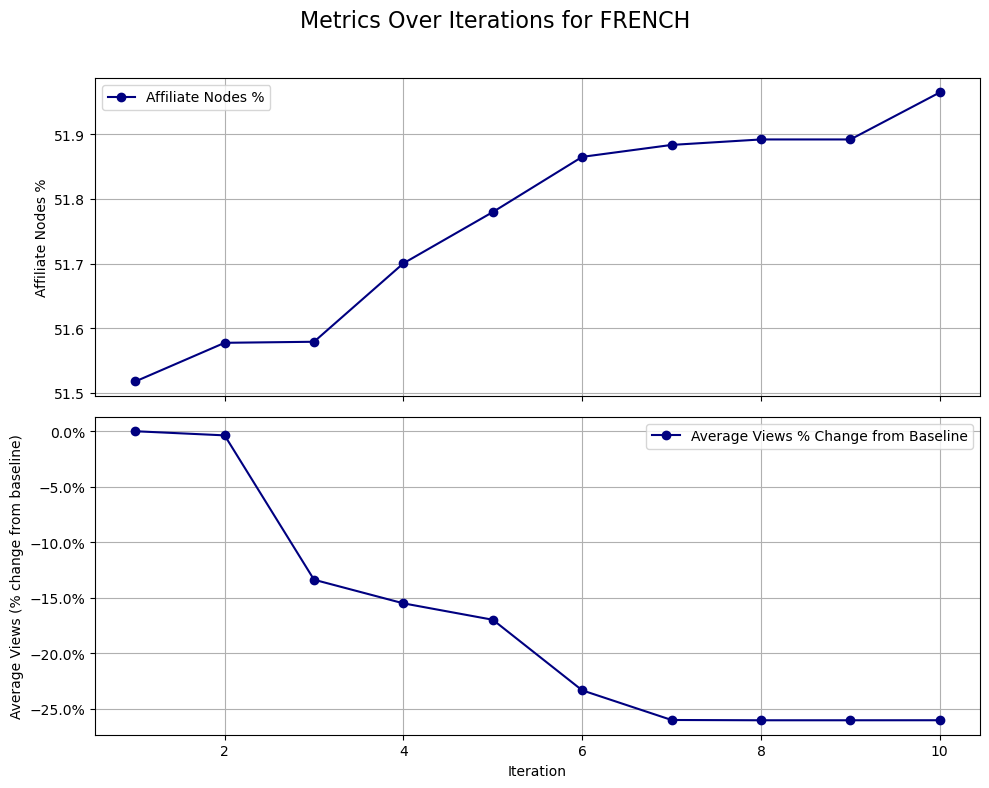

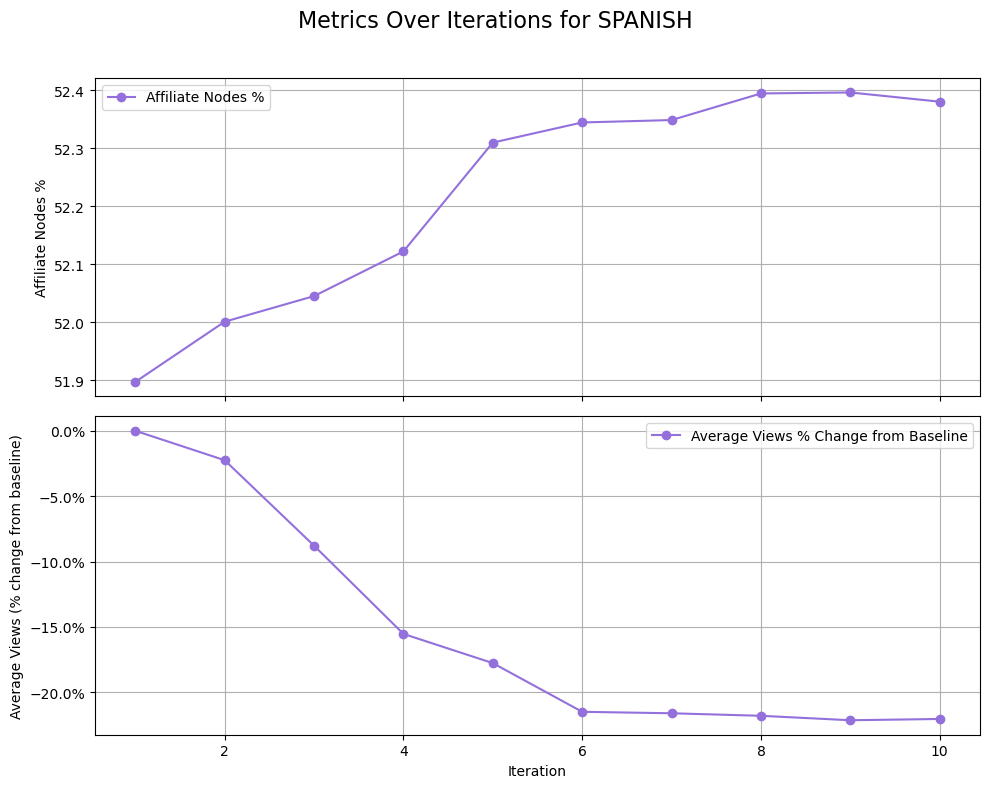

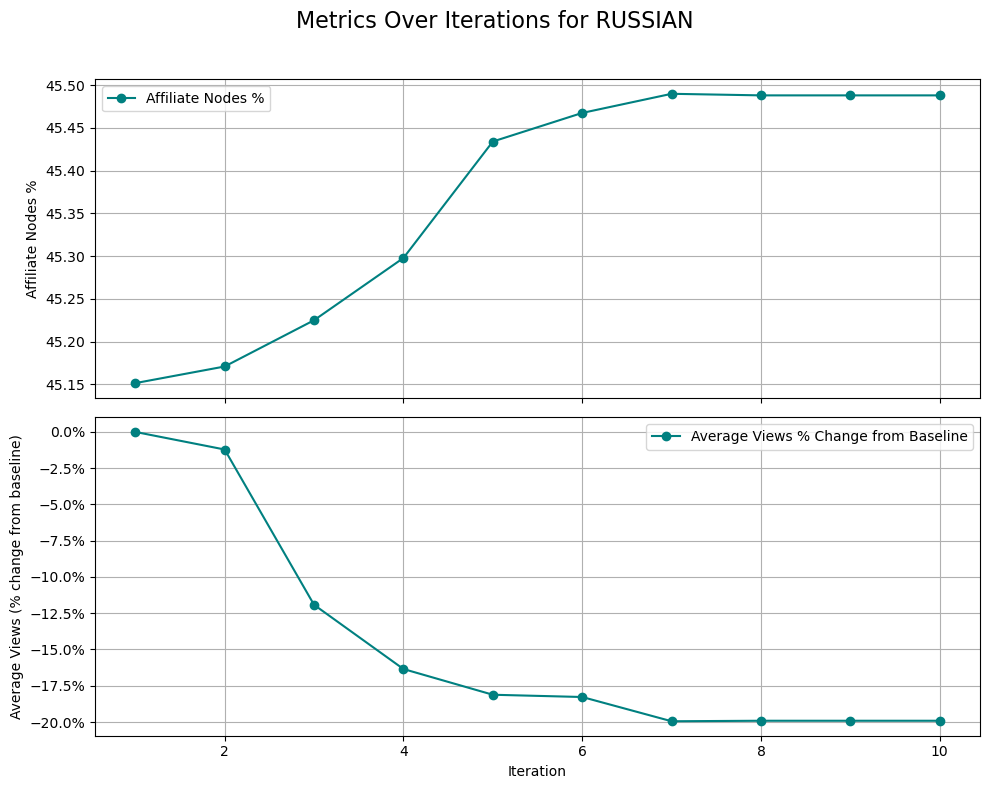

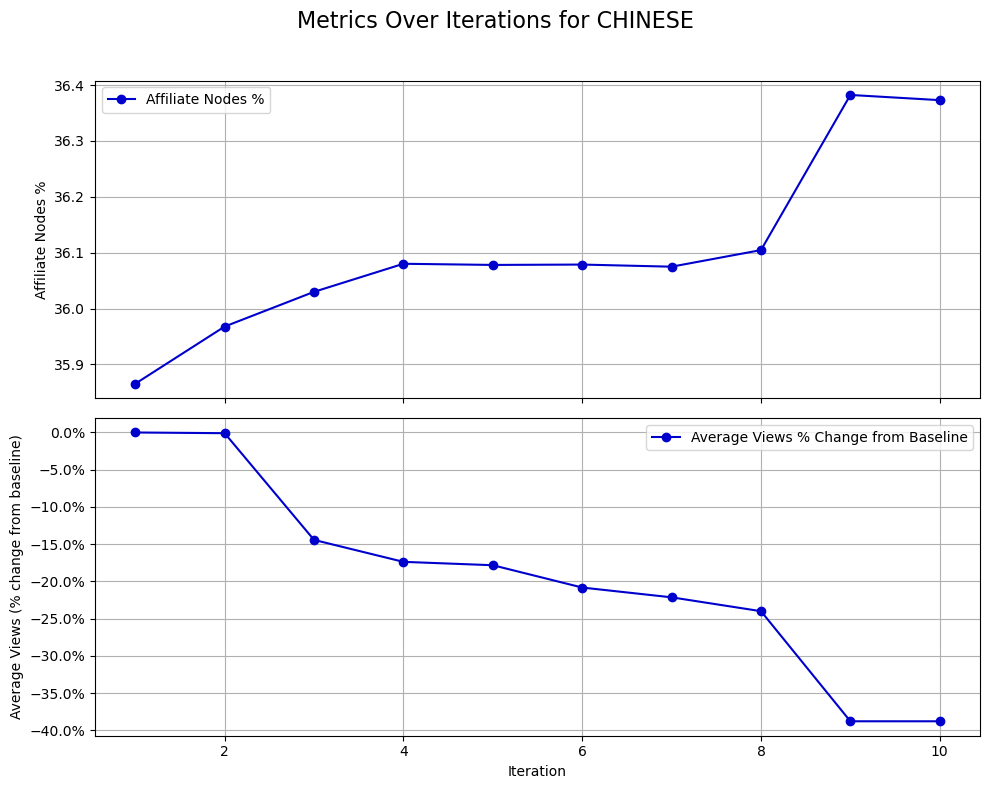

In [192]:
# Get all languages

all_metrics = {"FRENCH": fr_metrics, "SPANISH": es_metrics, "RUSSIAN": ru_metrics, 'CHINESE': zh_metrics}
colors = ['navy', 'mediumpurple', 'teal', 'mediumblue']
i = 0
for lang, metrics in all_metrics.items():
    plot_metrics_for_single_country(all_metrics[lang], country_label=lang, color=colors[i])
    i += 1

### Metrics


In [193]:
import numpy as np

def graph_summary(g):
    # Diameter and average geodesic length (handle disconnected graphs)
    try:
        diameter = g.diameter(directed=False, unconn=True)
    except Exception:
        diameter = None
    try:
        avg_geo = g.average_path_length(directed=False, unconn=True)
    except Exception:
        avg_geo = None

    # Number of nodes and edges
    n_nodes = g.vcount()
    n_edges = g.ecount()

    # Density
    density = g.density()

    # Percentage of affiliated nodes
    if "affiliate" in g.vs.attributes():
        affiliates = [a for a in g.vs["affiliate"] if a not in (None, "", False)]
        percent_affiliated = len(affiliates) / n_nodes * 100 if n_nodes > 0 else None
    else:
        percent_affiliated = None

    # View counts for boxplot
    if "views" in g.vs.attributes():
        views = np.array([int(v) for v in g.vs["views"]])
        if views.size > 0:
            view_summary = {
                "min": float(np.min(views)),
                "q1": float(np.percentile(views, 25)),
                "median": float(np.median(views)),
                "q3": float(np.percentile(views, 75)),
                "max": float(np.max(views)),
                "raw": views.tolist(),  # still return as a list for plotting
            }
        else:
            view_summary = None
    else:
        view_summary = None

    return {
        "num_nodes": n_nodes,
        "num_edges_total": n_edges,
        "density": density,
        "diameter": diameter,
        "average_geodesic_length": avg_geo,
        "percent_affiliated_nodes": percent_affiliated,
        "view_count_summary": view_summary,
    }


In [194]:
import matplotlib.pyplot as plt
import numpy as np

# Define consistent colors for each language
LANG_COLORS = {
    'French': 'navy',
    'Spanish': 'mediumpurple',
    'Russian': 'teal',
    'Chinese': 'mediumblue',
}

def plot_affiliation_barplot(summaries):
    languages = list(summaries.keys())
    percentages = [summaries[lang]['percent_affiliated_nodes'] for lang in languages]

    colors = [LANG_COLORS.get(lang, 'gray') for lang in languages]

    plt.figure(figsize=(9, 6))
    bars = plt.bar(languages, percentages, color=colors, edgecolor='black')
    plt.title("Percentage of Affiliated Nodes by Language", fontsize=16)
    plt.ylabel("Percent Affiliated Nodes", fontsize=14)
    plt.ylim(0, 100)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Add percentage labels on top of bars
    for bar, pct in zip(bars, percentages):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{pct:.1f}%", 
                 ha='center', va='bottom', fontsize=12)

    plt.tight_layout()
    plt.show()



In [195]:
import matplotlib.pyplot as plt
import numpy as np

def plot_degree_distribution(language_graphs, languages, max_degree_zoom=50):
    plt.figure(figsize=(12, 7))

    for g, lang in zip(language_graphs, languages):
        degrees = g.degree()
        filtered_degrees = [d for d in degrees if d <= max_degree_zoom]
        counts = np.bincount(filtered_degrees, minlength=max_degree_zoom + 1)

        plt.plot(range(max_degree_zoom + 1), counts, label=lang.capitalize(), 
                 color=LANG_COLORS.get(lang, 'gray'), linewidth=2.5)

    plt.title(f"Node Degree Distribution (Degree ≤ {max_degree_zoom})", fontsize=16)
    plt.xlabel("Degree", fontsize=14)
    plt.ylabel("Count", fontsize=14)
    plt.xlim(0, max_degree_zoom)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()


In [196]:

def plot_combined_viewcount_boxplot(summaries):
    data = []
    labels = []
    colors = []
    
    for lang, summary in summaries.items():
        view_summary = summary['view_count_summary']
        if view_summary and view_summary.get("raw"):
            data.append(view_summary["raw"])
            labels.append(lang.capitalize())
            colors.append(LANG_COLORS.get(lang, '#aabbcc'))
    
    plt.figure(figsize=(12, 7))
    bplot = plt.boxplot(data, vert=False, patch_artist=True, labels=labels)
    
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    for median in bplot['medians']:
        median.set_color('navy')
        median.set_linewidth(2)
    
    plt.xscale('log')  # <<< Here’s the log scale
    
    plt.title("View Count Distribution by Language", fontsize=16)
    plt.xlabel("View Count (log scale)")
    plt.tight_layout()
    plt.show()


In [197]:
# Loop through and get metrics for each language graph 
languages = ["French", "Spanish", "Russian", "Chinese"]
language_graphs = [french_g, spanish_g, russian_g, chinese_g]

# Run graph summaries
summaries = {lang: graph_summary(g) for lang, g in zip(languages, language_graphs)}

In [73]:
print(summaries)

{'French': {'num_nodes': 7355, 'num_edges_total': 123529, 'density': 0.00456764790112236, 'diameter': 7, 'average_geodesic_length': 2.792416269521974, 'percent_affiliated_nodes': 51.0944935418083, 'view_count_summary': {'min': 21.0, 'q1': 2349.5, 'median': 7057.0, 'q3': 24887.5, 'max': 179513429.0, 'raw': [7941991, 730, 2774, 1824, 17166188, 3949798, 58059, 64744, 76838, 288, 1026449, 1220, 15761, 8669, 2869, 1208, 2435, 8754, 5536, 9304, 42801507, 148, 135449, 2541300, 9194058, 19120, 308989, 1084, 22960, 2192, 7110, 4142, 7302, 30798, 1425, 2113, 1519, 231, 677, 109652, 4957, 613, 9770, 7016, 2603, 2957, 3644, 3553, 557, 74767, 3347, 2769, 8145, 11524, 43110, 1183, 9856, 3317, 36094, 975, 2050, 1428, 1953, 2220, 2406, 28066, 4290, 7424471, 7558, 450, 1907, 11571, 1609, 6452, 1968, 8387, 608110, 44374644, 4592052, 4503, 2199, 1759, 9434, 234114, 361, 1785, 52, 52401, 42955, 30347, 31636, 4297, 5815, 9866, 22239, 4438548, 923, 1704, 121, 8916, 3240, 194377, 14022, 35206, 5918, 12074, 5

In [198]:

# Run graph summaries and keep only the median from the view summary
summaries_2 = {}
for lang, g in zip(languages, language_graphs):
    summary = graph_summary(g)
    view_summary = summary.pop("view_count_summary", None)
    if view_summary and isinstance(view_summary, dict):
        summary["median_view_count"] = view_summary.get("median")
    else:
        summary["median_view_count"] = None
    summaries_2[lang] = summary

In [75]:
print(summaries_2)

{'French': {'num_nodes': 7355, 'num_edges_total': 123529, 'density': 0.00456764790112236, 'diameter': 7, 'average_geodesic_length': 2.792416269521974, 'percent_affiliated_nodes': 51.0944935418083, 'median_view_count': 7057.0}, 'Spanish': {'num_nodes': 5965, 'num_edges_total': 85984, 'density': 0.004833921101349645, 'diameter': 8, 'average_geodesic_length': 2.9674432706604903, 'percent_affiliated_nodes': 51.46689019279128, 'median_view_count': 5440.0}, 'Russian': {'num_nodes': 5071, 'num_edges_total': 46696, 'density': 0.003632520769180205, 'diameter': 8, 'average_geodesic_length': 2.9995075067846275, 'percent_affiliated_nodes': 44.82350621179255, 'median_view_count': 11966.0}, 'Chinese': {'num_nodes': 3209, 'num_edges_total': 67532, 'density': 0.013120051227493747, 'diameter': 6, 'average_geodesic_length': 2.588281877985322, 'percent_affiliated_nodes': 35.74322218759738, 'median_view_count': 18645.0}}


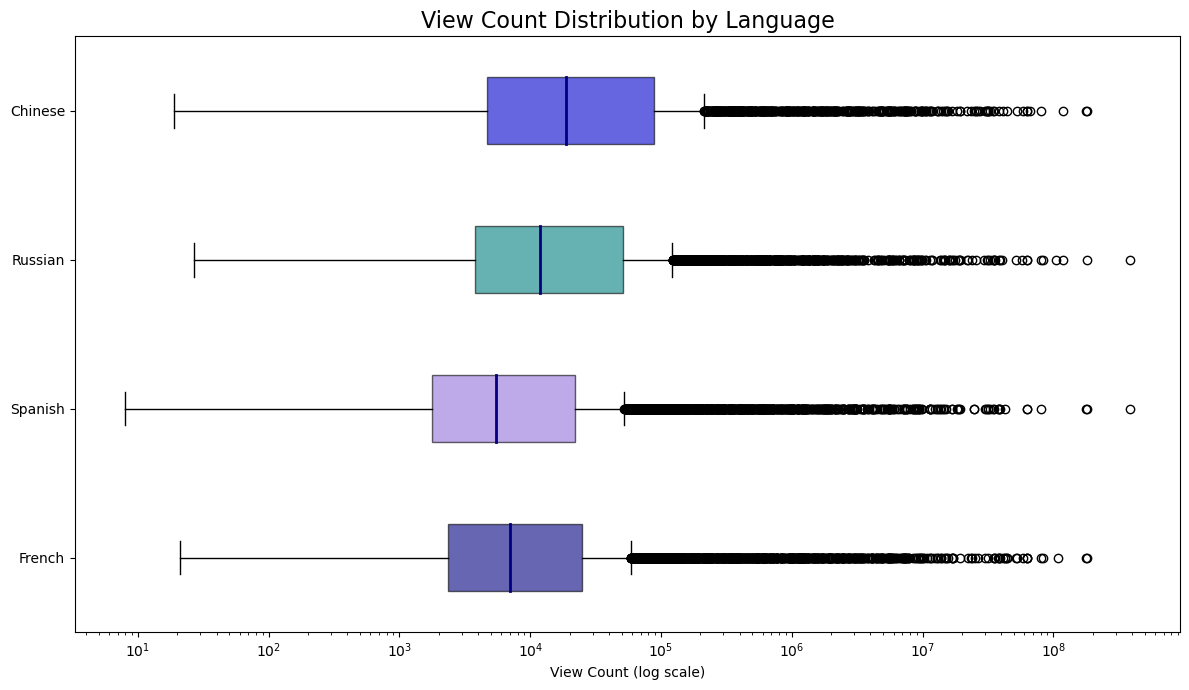

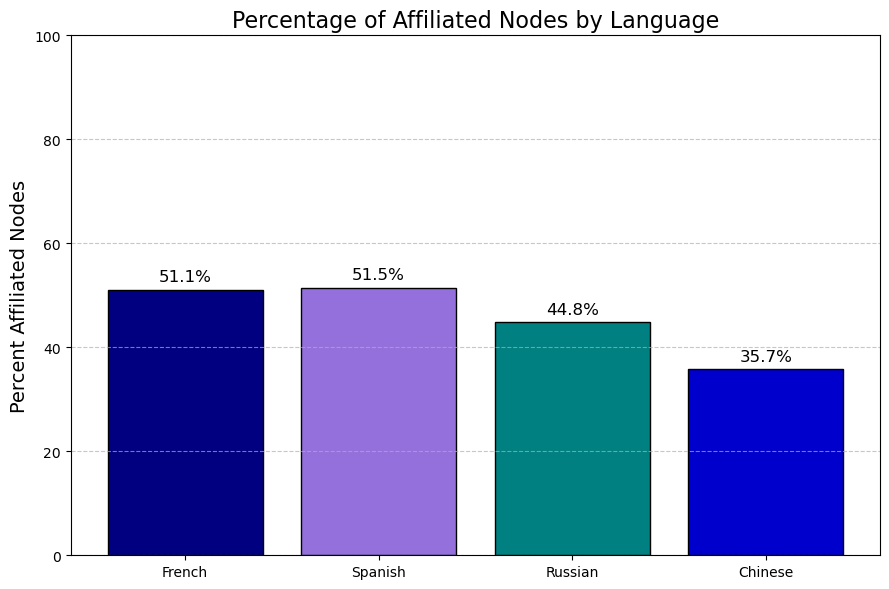

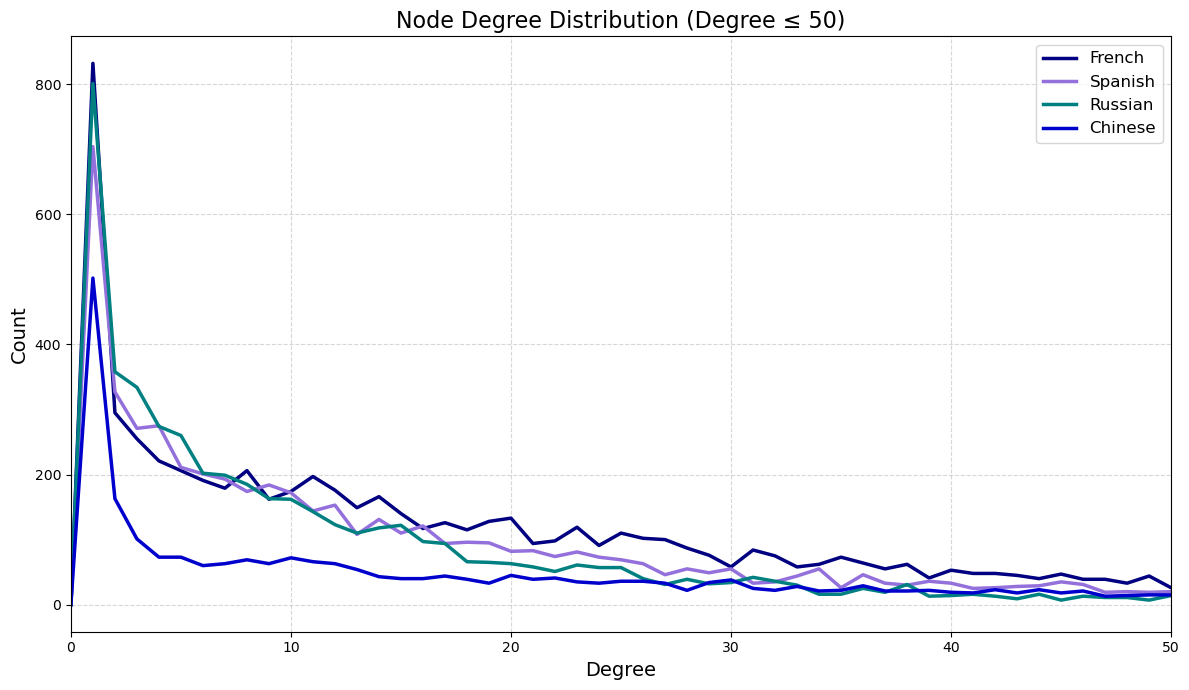

In [199]:
import matplotlib.pyplot as plt

# Generate visualizations with pastel blues and purples styling
plot_combined_viewcount_boxplot(summaries)
plot_affiliation_barplot(summaries)
plot_degree_distribution(language_graphs, languages)


In [134]:
import pandas as pd

# Original dataframe construction (as you have it)
vertex_data = pd.DataFrame({
    "numeric_id": entire_g.vs["name"],
    "degree": entire_g.degree(),
    "eigen_centrality": entire_g.eigenvector_centrality(),
    "views": entire_g.vs["views"],
    "life_time": entire_g.vs["life_time"],
    "affiliate": entire_g.vs["affiliate"],
    "language": entire_g.vs["language"]
})

# Drop missing data for necessary columns
vertex_data.dropna(subset=["degree", "affiliate", "views", "life_time", "language"], inplace=True)

# Ensure correct types
vertex_data["affiliate"] = vertex_data["affiliate"].astype(int)
vertex_data["views"] = vertex_data["views"].astype(float)
vertex_data["life_time"] = vertex_data["life_time"].astype(float)

display(vertex_data)

,numeric_id,degree,eigen_centrality,views,life_time,affiliate,language
0,27198,569,1.685465e-02,7941991.0,1205.0,0,FR
1,148201,7,5.089595e-04,730.0,1920.0,0,FR
2,6662,28,1.790069e-03,2774.0,2010.0,1,FR
3,151911,12,6.855853e-04,1824.0,1783.0,0,FR
4,73257,1710,2.472070e-02,17166188.0,2419.0,0,FR
...,...,...,...,...,...,...,...
19398,32235,1,4.624514e-08,8723.0,1082.0,1,RU
19399,71698,1,4.603789e-08,2866.0,641.0,1,ES
19400,81029,1,1.018435e-07,2830.0,422.0,1,FR
19401,53930,1,2.424572e-07,490.0,3058.0,0,ES


In [136]:
# Dictionary to hold language-specific dataframes (for df_degree)
dfs_by_language = {}

for lang in languages:
    dfs_by_language[lang] = vertex_data[vertex_data['language'] == lang].copy()


In [ ]:
# import statsmodels.api as sm
# import statsmodels.formula.api as smf

# # Function to fite each df
# def lin_regress(df):

#     lang = df.iloc[0]['language']

#     # Define the formula: views ~ eigen_centrality + affiliate
#     formula = 'views ~ eigen_centrality + affiliate'

#     # Fit the model using ols
#     model = smf.ols(formula=formula, data=df).fit(cov_type='HC3')  # HC3 robust SEs

#     # Print the summary with robust standard errors
#     print(lang)
#     print(model.summary())
    

In [151]:
def add_centrality_attributes(g, eigen_attr='eigenvector_centrality', degree_attr='degree'):
    """
    Compute eigenvector and degree centralities and add them as vertex attributes to graph g.
    
    Parameters:
    - g: igraph Graph
    - eigen_attr: attribute name to store eigenvector centrality
    - degree_attr: attribute name to store degree centrality (usually 'degree')
    
    Returns:
    - None (modifies graph g inplace)
    """
    # Compute eigenvector centrality (normalized)
    eigen_centrality = g.eigenvector_centrality()
    g.vs[eigen_attr] = eigen_centrality

    # Compute degree centrality
    degree_centrality = g.degree()
    g.vs[degree_attr] = degree_centrality

In [165]:
for g in [french_g, spanish_g, russian_g, chinese_g]:
    add_centrality_attributes(g)

add_centrality_attributes(entire_g)

In [171]:
from scipy.stats import pearsonr
import numpy as np

def pearson_coefficients_pvalues_overlap_from_graph(
    g,
    views_attr='views',
    eigen_attr='eigenvector_centrality',
    degree_attr='degree',
    top_n=100
):
    """
    Compute Pearson correlation coefficients, p-values, and percent overlaps
    between views and eigenvector centrality, and between views and degree centrality
    for top_n nodes selected by views or centralities.
    """
    # Check for attributes
    for attr in [views_attr, eigen_attr]:
        if attr not in g.vs.attributes():
            raise ValueError(f"Graph vertices must have attribute '{attr}'")

    views = g.vs[views_attr]
    eigen = g.vs[eigen_attr]
    degree = g.degree() if degree_attr == 'degree' else g.vs[degree_attr]

    def top_n_nodes(attr_list):
        valid = [(i, val) for i, val in enumerate(attr_list) if val is not None and not (isinstance(val, float) and np.isnan(val))]
        valid_sorted = sorted(valid, key=lambda x: x[1], reverse=True)
        return [idx for idx, val in valid_sorted[:top_n]]

    top_views_idx = top_n_nodes(views)
    top_eigen_idx = top_n_nodes(eigen)
    top_degree_idx = top_n_nodes(degree)

    def ordered_union(list1, list2):
        seen = set(list1)
        return list1 + [x for x in list2 if x not in seen]

    union_eigen_idx = ordered_union(top_views_idx, top_eigen_idx)
    union_degree_idx = ordered_union(top_views_idx, top_degree_idx)

    def extract_values(indices, attr1, attr2):
        vals1, vals2 = [], []
        for i in indices:
            v1, v2 = attr1[i], attr2[i]
            if v1 is None or v2 is None:
                continue
            if (isinstance(v1, float) and np.isnan(v1)) or (isinstance(v2, float) and np.isnan(v2)):
                continue
            vals1.append(v1)
            vals2.append(v2)
        return vals1, vals2

    eigen_vals, views_vals_eigen = extract_values(union_eigen_idx, eigen, views)
    degree_vals, views_vals_degree = extract_values(union_degree_idx, degree, views)

    def safe_pearsonr(x, y):
        if len(x) < 2:
            return np.nan, np.nan
        if all(val == x[0] for val in x) or all(val == y[0] for val in y):
            return np.nan, np.nan
        return pearsonr(x, y)

    eigen_corr, eigen_p = safe_pearsonr(eigen_vals, views_vals_eigen)
    degree_corr, degree_p = safe_pearsonr(degree_vals, views_vals_degree)

    overlap_eigen = len(set(top_views_idx).intersection(set(top_eigen_idx))) / top_n * 100
    overlap_degree = len(set(top_views_idx).intersection(set(top_degree_idx))) / top_n * 100

    return {
        'eigen_pearson_r': eigen_corr,
        'eigen_p_value': eigen_p,
        'eigen_percent_overlap': overlap_eigen,
        'degree_pearson_r': degree_corr,
        'degree_p_value': degree_p,
        'degree_percent_overlap': overlap_degree,
    }

In [173]:
import pandas as pd

languages = ["French", "Spanish", "Russian", "Chinese"]
language_graphs = [french_g, spanish_g, russian_g, chinese_g]
results = {}
for lang, g in zip(languages, language_graphs):
    results[lang] = pearson_coefficients_pvalues_overlap_from_graph(g, top_n=100)

# Convert results dict into DataFrame
df_results = pd.DataFrame.from_dict(results, orient='index').reset_index()
df_results = df_results.rename(columns={'index': 'language'})

# Compute overall results
overall_results = pearson_coefficients_pvalues_overlap_from_graph(entire_g, top_n=500)

# Convert overall results dict to DataFrame with one row
df_overall = pd.DataFrame([overall_results])
df_overall['language'] = 'Overall'

# Append overall results
df_results = pd.concat([df_results, df_overall], ignore_index=True)

# Add significance columns
df_results['eigen_significant'] = df_results['eigen_p_value'] < 0.05
df_results['degree_significant'] = df_results['degree_p_value'] < 0.05

# Now just display
display(df_results)

,language,eigen_pearson_r,eigen_p_value,eigen_percent_overlap,degree_pearson_r,degree_p_value,degree_percent_overlap,eigen_significant,degree_significant
0,French,-0.079030,0.302762,28.0,-0.025468,7.416567e-01,30.0,False,False
1,Spanish,-0.256338,0.000533,21.0,-0.189212,1.265930e-02,27.0,True,True
2,Russian,0.077944,0.321173,36.0,0.217054,8.970336e-03,56.0,False,True
3,Chinese,0.088188,0.275196,45.0,0.220641,7.044100e-03,52.0,False,True
4,Overall,0.044129,0.191933,24.8,0.309944,1.315193e-17,55.0,False,True


In [174]:
# Assuming your DataFrame is named df_results

# Save as CSV
df_results.to_csv('pearson_correlation_results.csv', index=False, sep="|")
